# Blood cell type classification

### Imports

In [1]:
import os
import torch
import cv2
import glob
import matplotlib.pyplot as plt
import random
import numpy as np
from pathlib import Path
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import kagglehub

### Utils functions

In [17]:
def calculate_mean_and_std(dataloader):
    channels_sum = torch.zeros(3)
    channels_squared_sum = torch.zeros(3)
    total_pixels = 0

    for images, _ in dataloader:
        batch_pixels = images.size(0) * images.size(2) * images.size(3)
        total_pixels += batch_pixels

        channels_sum += torch.sum(images, dim=[0, 2, 3])
        channels_squared_sum += torch.sum(images ** 2, dim=[0, 2, 3])

    mean = channels_sum / total_pixels
    std = torch.sqrt((channels_squared_sum / total_pixels) - (mean ** 2))

    return mean, std


def load_image_list(image_paths):
    images = []
    for image_path in image_paths:
        images.append(cv2.imread(image_path))

    return images


def visualize_images(image_list, cell_type, rows, columns, size_mod=4):
    fig, axes = plt.subplots(rows,
                             columns,
                             figsize=(columns * size_mod, rows * size_mod))

    fig.suptitle(f"Cell type - {cell_type}")

    if isinstance(axes, plt.Axes):
        axes_list = [axes]
    else:
        axes_list = axes.flat

    for index, axis in enumerate(axes_list):
        if index < len(image_list):
            axis.imshow(image_list[index])
        axis.axis('off')

    plt.tight_layout()
    plt.show()

### Loading in the dataset

In [3]:
path = kagglehub.dataset_download("paultimothymooney/blood-cells")

100%|██████████| 108M/108M [00:01<00:00, 98.3MB/s] 

Extracting files...


In [4]:
train_dir = f"{path}/dataset2-master/dataset2-master/images/TRAIN"
test_dir = f"{path}/dataset2-master/dataset2-master/images/TEST"

data_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

# Since dataset has the PyTorch-friendly structure (each class has its
# own subfolder within TRAIN and TEST folders) we can just use the
# .ImageFolder() method to create PyTorch Datasets instances.
train_dataset = datasets.ImageFolder(train_dir, transform=data_transforms)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)

# Calculating mean and standard deviation of the dataset images
mean, std = calculate_mean_and_std(train_loader)

In [5]:
train_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean.tolist(), std=std.tolist())
])

test_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean.tolist(), std=std.tolist())
])

train_dataset = datasets.ImageFolder(train_dir, transform=train_transforms)
test_dataset = datasets.ImageFolder(test_dir, transform=test_transforms)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

### Data visualization

In [6]:
print(os.listdir(train_dir))

['MONOCYTE', 'EOSINOPHIL', 'LYMPHOCYTE', 'NEUTROPHIL']


In [10]:
cell_images_paths = {}
random_cell_images = {}
images_per_visualization = 9
rows, columns = 3, 3

for cell_type in os.listdir(train_dir):
    folder_path = Path(train_dir) / cell_type
    images_paths = [str(file_path) for file_path in folder_path.iterdir() if file_path.is_file()]
    cell_images_paths[cell_type] = images_paths

    random_cell_images_paths = random.choices(images_paths, k=images_per_visualization)
    random_cell_images_list = [
         cv2.imread(random_cell_images_paths[i])
         for i in range(images_per_visualization)
         ]

    random_cell_images[cell_type] = random_cell_images_list

#### 9 Randomly selected images for every blood type

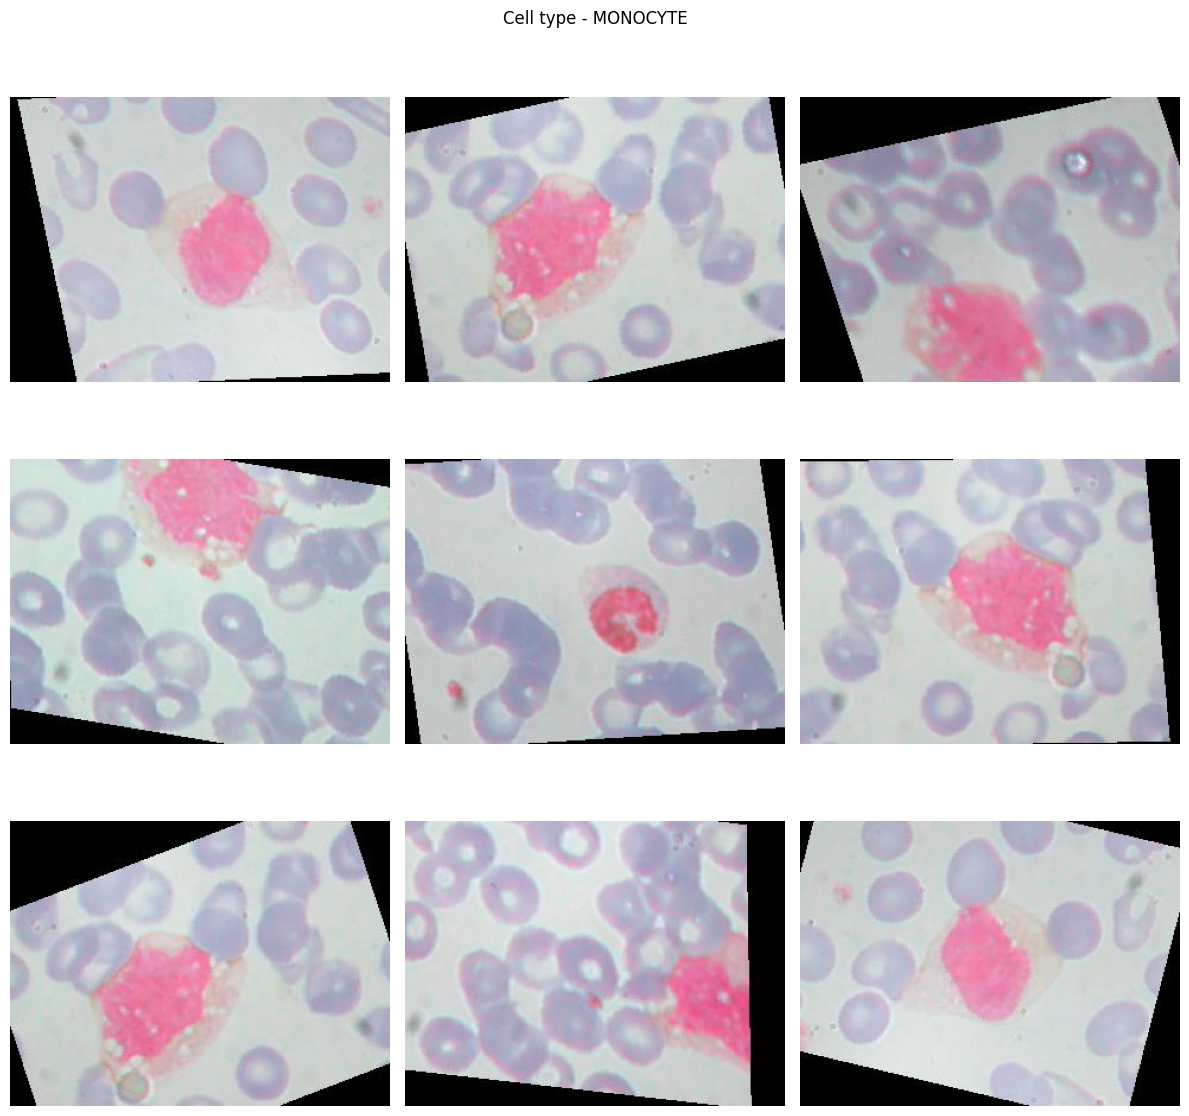

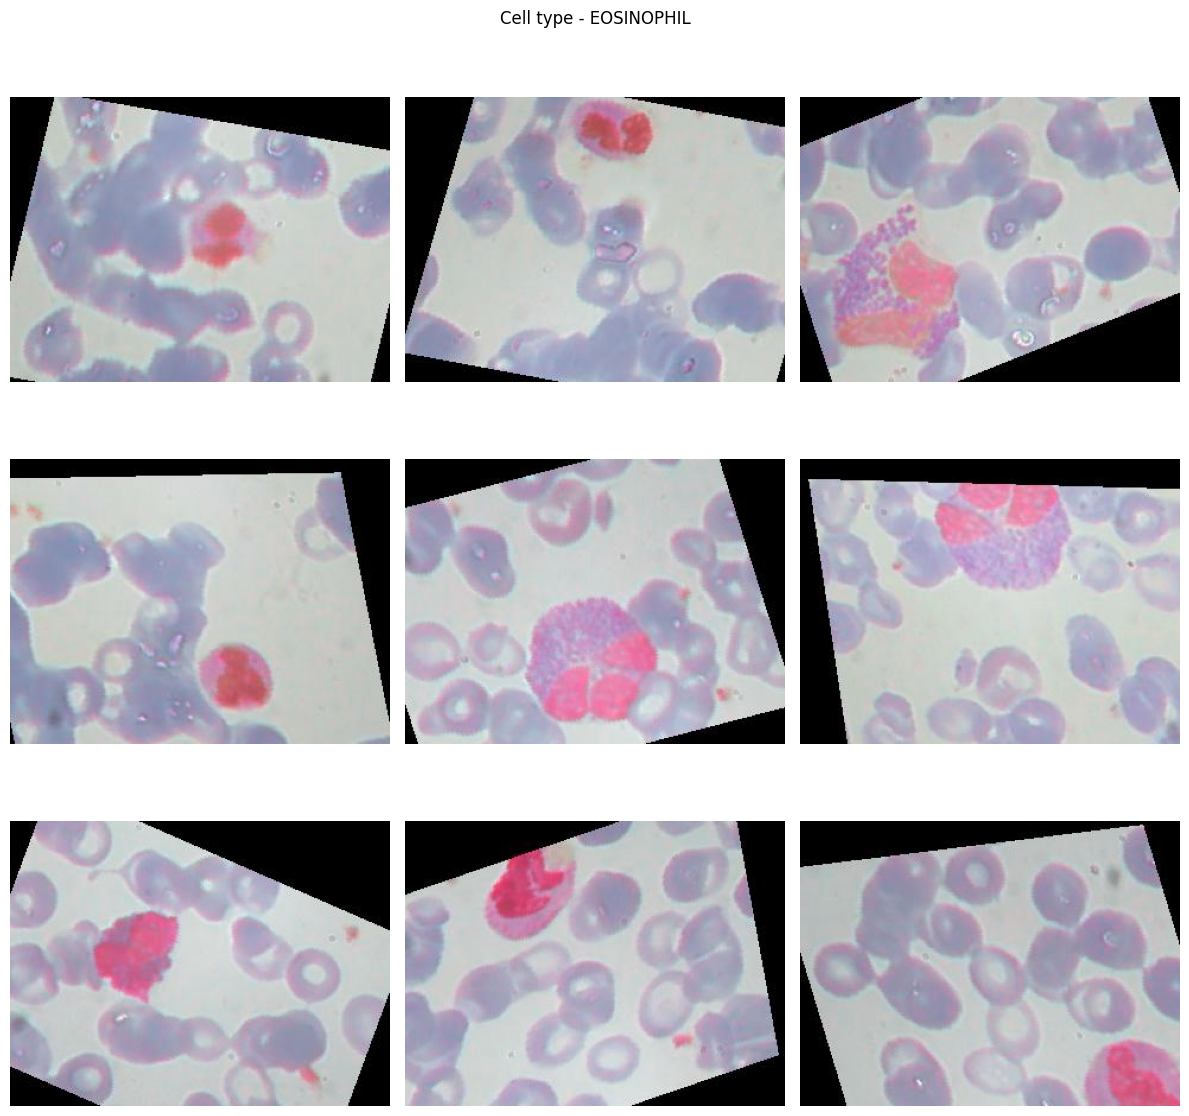

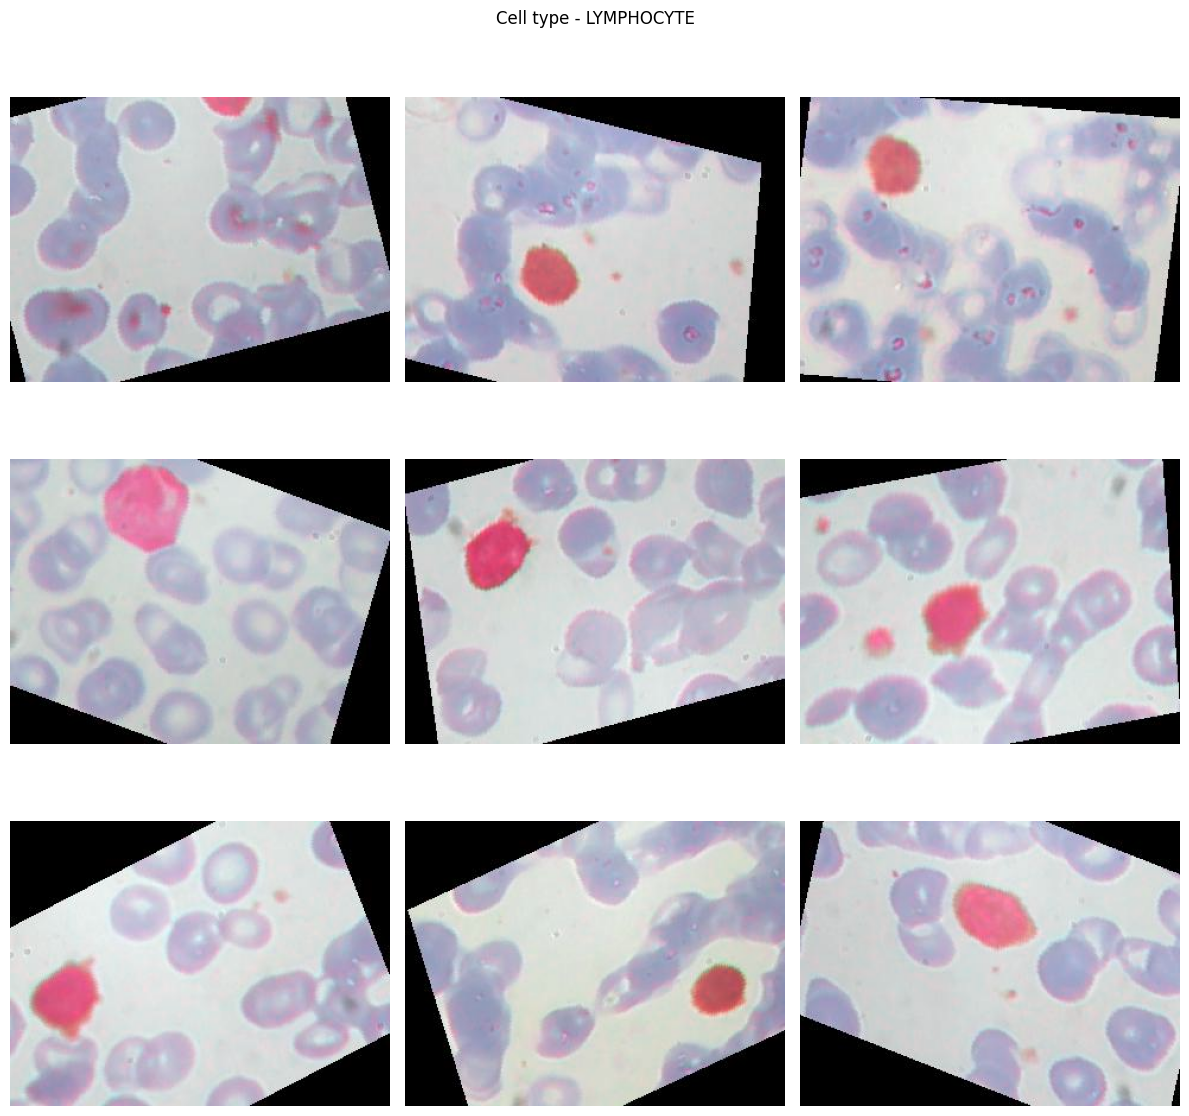

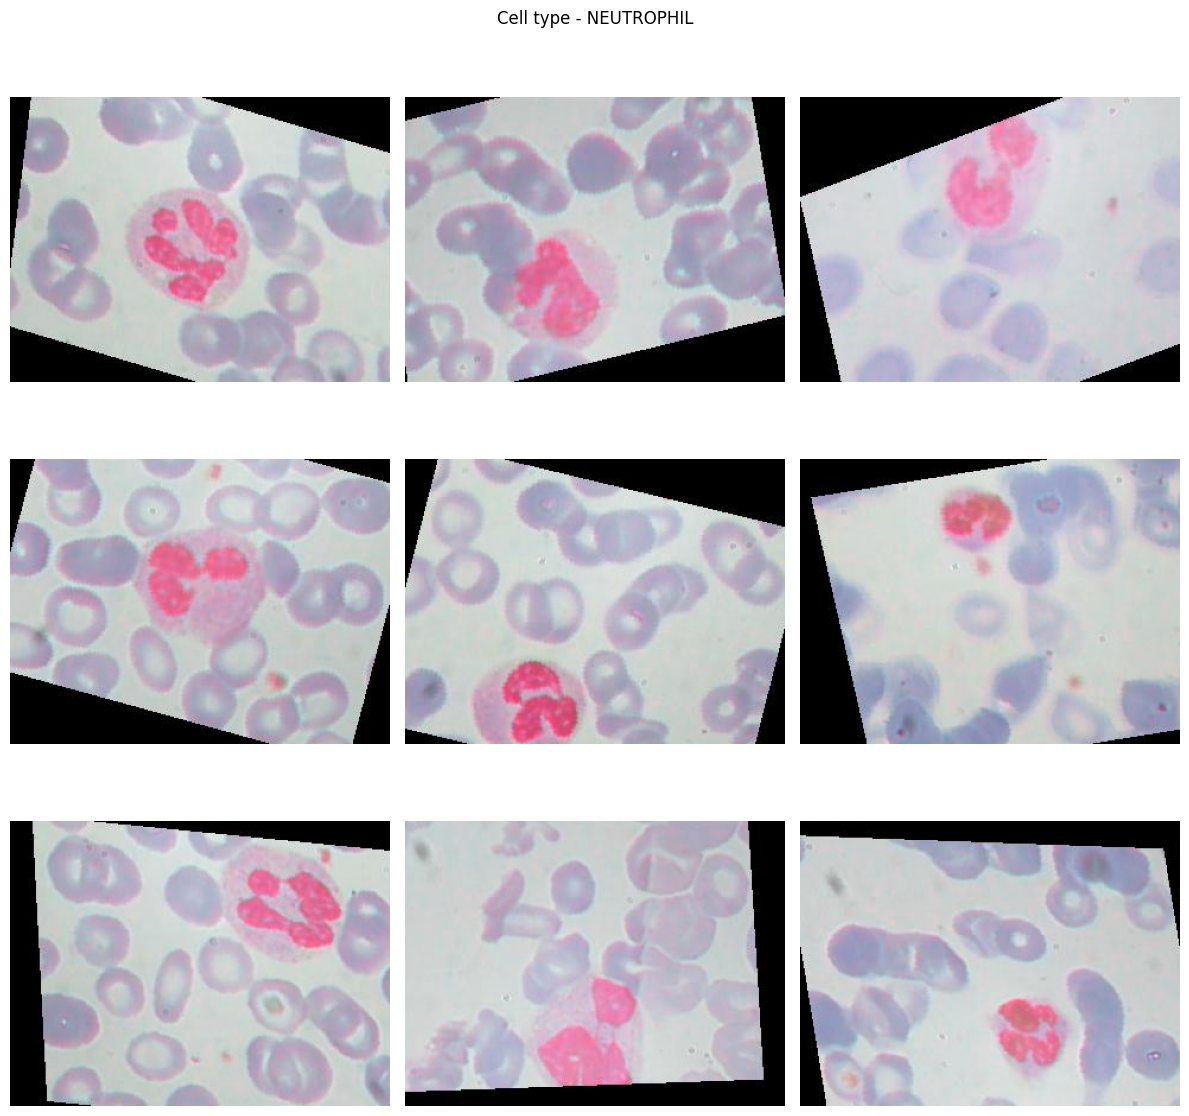

In [11]:
for cell_type, cell_image_list in random_cell_images.items():
    visualize_images(cell_image_list, cell_type, 3, 3)

#### Checking for class imbalance

In [12]:
cell_images_count = {}

for cell_type in os.listdir(train_dir):
  image_count = sum(1 for item in folder_path.iterdir() if item.is_file())
  cell_images_count[cell_type] = image_count

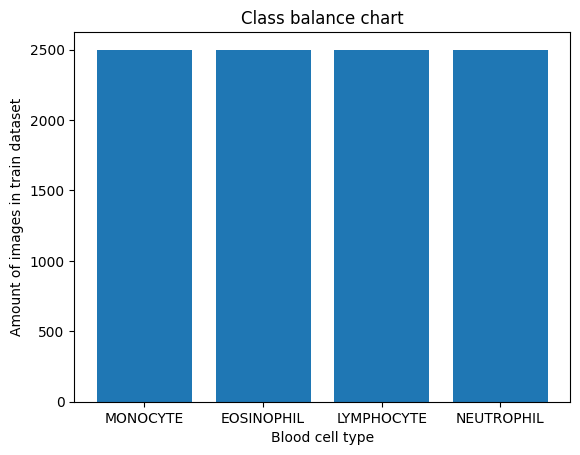

In [13]:
fig, ax = plt.subplots()

ax.bar(cell_images_count.keys(), cell_images_count.values())

ax.set_xlabel("Blood cell type")
ax.set_ylabel("Amount of images in train dataset")
ax.set_title("Class balance chart")

fig.show()

Every class has the same representation, so there is no need to combat the class imbalance.

### Checking aspect ratio

In [14]:
aspect_ratios = []

for cell_type in os.listdir(train_dir):
    folder_path = Path(train_dir) / cell_type
    images_paths = [str(file_path) for file_path in folder_path.iterdir() if file_path.is_file()]

    for image_path in images_paths:
        image = cv2.imread(image_path)
        aspect_ratios.append((image.shape[0], image.shape[1]))

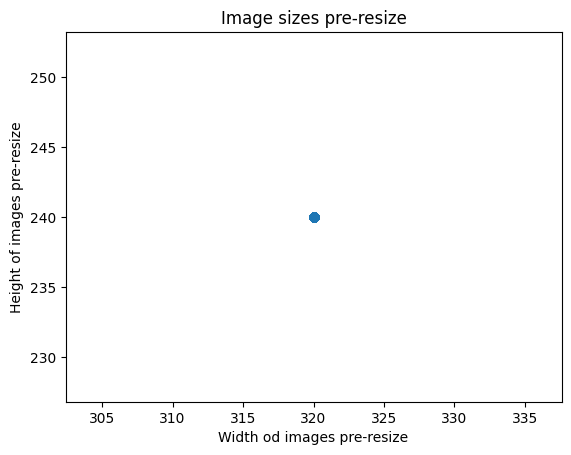

In [15]:
height_list, width_list = map(list, zip(*aspect_ratios))

fig, ax = plt.subplots()

ax.scatter(width_list, height_list)

ax.set_xlabel("Width od images pre-resize")
ax.set_ylabel("Height of images pre-resize")
ax.set_title("Image sizes pre-resize")

fig.show()

All images have the same shape before scaling - 320x240 pixels, so there should be no difference in how rescaling affects them. The new size - 224x224 is similar enough that resizing should not be problematic.

#### Checking brightness and color distribution

In [16]:
def average_brightness(images):
    brightness_list = []
    for image in images:

        b, g, r = cv2.split(image)

        mean_brightness = (r.mean() + g.mean() + b.mean()) / 3.0
        brightness_list.append(mean_brightness)

    return brightness_list


def channel_histograms(images):
    hist_r = np.zeros(256, dtype=np.int64)
    hist_g = np.zeros(256, dtype=np.int64)
    hist_b = np.zeros(256, dtype=np.int64)

    for image in images:
        b, g, r = cv2.split(image)

        hist_b += cv2.calcHist([b],
                               [0],
                               None,
                               [256],
                               [0, 256]).ravel().astype(np.int64)

        hist_g += cv2.calcHist([g],
                               [0],
                               None,
                               [256],
                               [0, 256]).ravel().astype(np.int64)

        hist_r += cv2.calcHist([r],
                               [0],
                               None,
                               [256],
                               [0, 256]).ravel().astype(np.int64)

    return hist_r, hist_g, hist_b

In [18]:
brightness_lists = {}

for cell_type in os.listdir(train_dir):
    images = load_image_list(cell_images_paths[cell_type])
    brightness_lists[cell_type] = average_brightness(images)

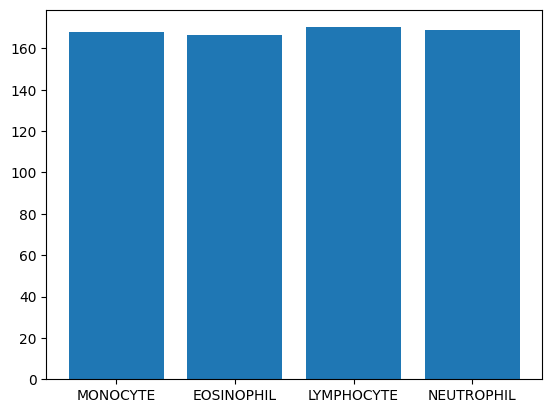

In [28]:
plt.bar(brightness_lists.keys(), [np.average(value) for value in brightness_lists.values()])
plt.show()

The average brightness for all image classes are almost the same.

In [29]:
color_distributions = {}

for cell_type in os.listdir(train_dir):
    images = load_image_list(cell_images_paths[cell_type])
    color_distributions[cell_type] = (channel_histograms(images))

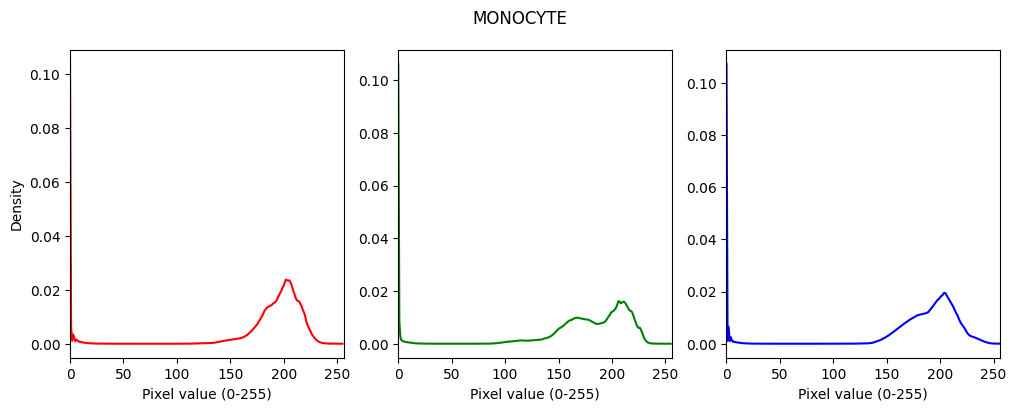

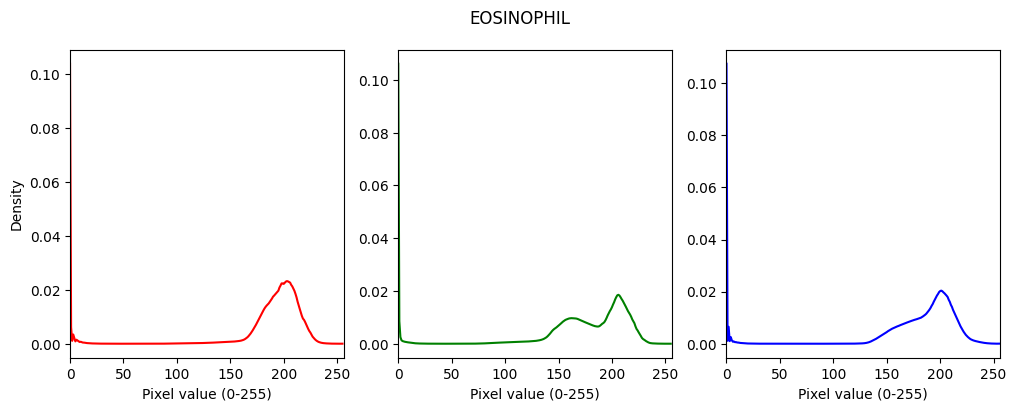

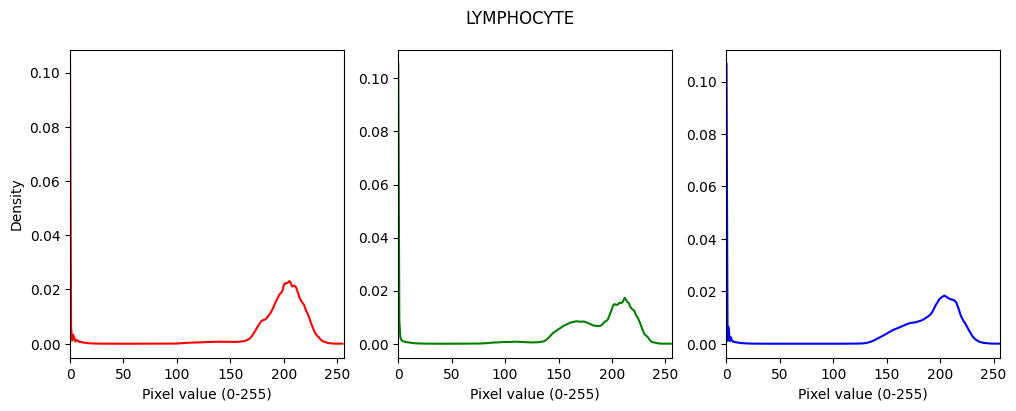

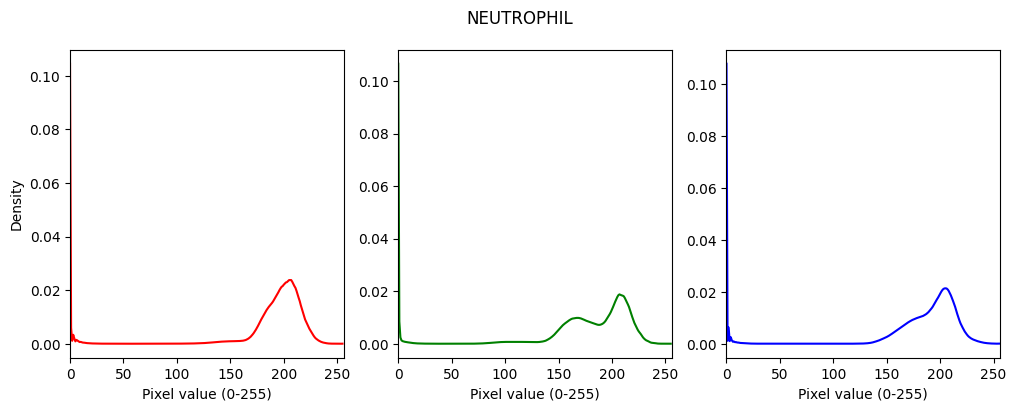

In [39]:
for cell_type in color_distributions:
    fig, ax = plt.subplots(1, 3, figsize=(12, 4))
    fig.suptitle(cell_type)

    total_pixels = sum(color_distributions[cell_type][0])
    ax[0].plot(color_distributions[cell_type][0] / total_pixels, color="red", label="Red")
    ax[1].plot(color_distributions[cell_type][1] / total_pixels, color="green", label="Green")
    ax[2].plot(color_distributions[cell_type][2] / total_pixels, color="blue", label="Blue")

    ax[0].set_ylabel("Density")
    for i in range(3):
        ax[i].set_xlim([0, 256])
        ax[i].set_xlabel("Pixel value (0-255)")


    plt.show()

Due to image flipping, which created large fields of black pixels all the images have large spikes in density for pixel value of 0. We can visualzie histograms again and skip this value.

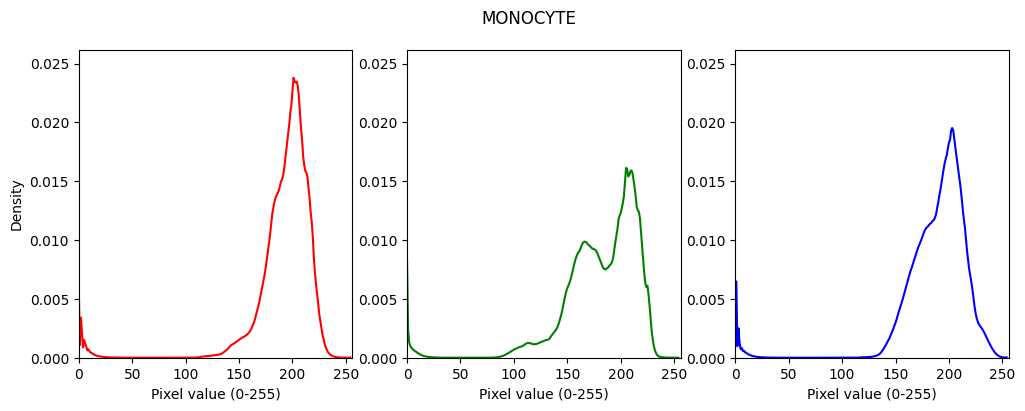

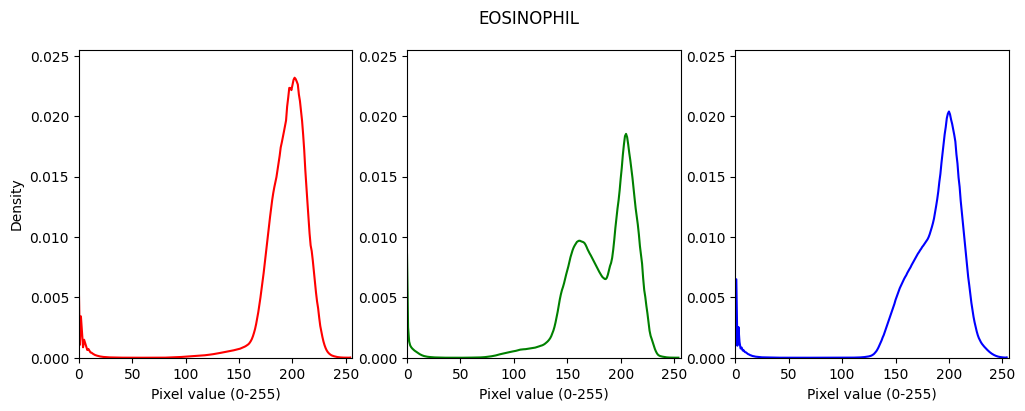

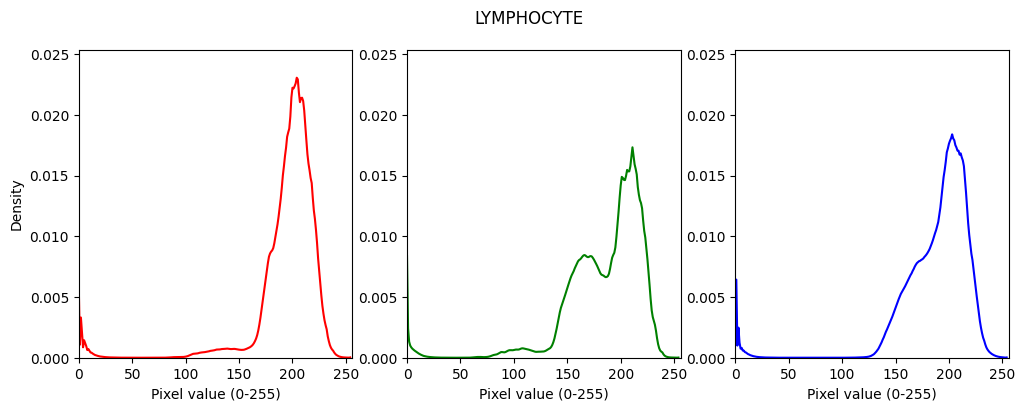

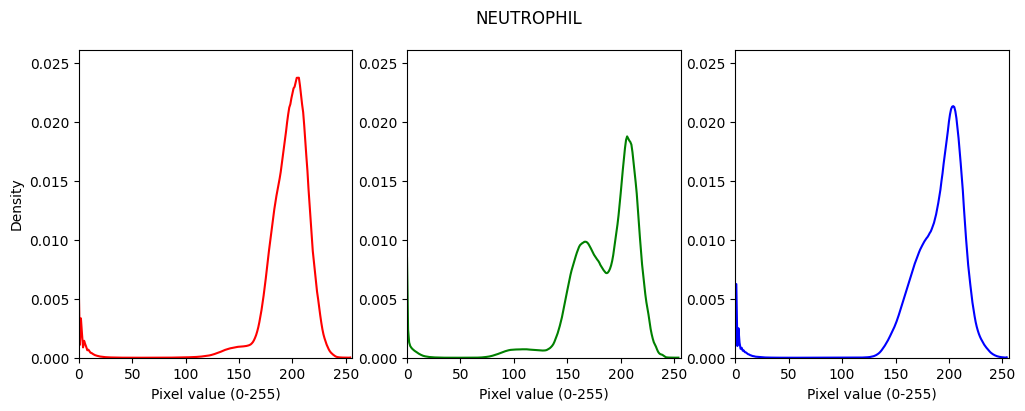

In [44]:
for cell_type in color_distributions:
    fig, ax = plt.subplots(1, 3, figsize=(12, 4))
    fig.suptitle(cell_type)

    total_pixels = sum(color_distributions[cell_type][0])
    ax[0].plot(color_distributions[cell_type][0][1:] / total_pixels, color="red", label="Red")
    ax[1].plot(color_distributions[cell_type][1][1:] / total_pixels, color="green", label="Green")
    ax[2].plot(color_distributions[cell_type][2][1:] / total_pixels, color="blue", label="Blue")

    r_density = color_distributions[cell_type][0][1:] / total_pixels
    g_density = color_distributions[cell_type][1][1:] / total_pixels
    b_density = color_distributions[cell_type][2][1:] / total_pixels
    max_y = max(r_density.max(), g_density.max(), b_density.max()) * 1.1

    ax[0].set_ylabel("Density")
    for i in range(3):
        ax[i].set_xlim([0, 256])
        ax[i].set_ylim([0, max_y])
        ax[i].set_xlabel("Pixel value (0-255)")


    plt.show()

All classes have similar spikes in density for values around 150-230. Since there is little distinction between the average brightness of images of each cell types, as well as their color histograms, the models will have to focus primarily on the shape of a cell, rather than its color.